# 1. Entropy

**Cover and Thomas, Section 2.1.**

For a discrete random variable $X$ with alphabet $\mathcal X$ and probability
mass function $p(x) = \Pr\{X = x\}$,

$$H(X) \;=\; -\sum_{x \in \mathcal X} p(x) \log p(x) \;=\; \mathbb E_p \log \frac{1}{p(X)} .$$

The logarithm is base 2, so $H$ is measured in **bits**. The convention
$0 \log 0 = 0$ is used, justified by continuity since $t \log t \to 0$ as
$t \to 0$.

Entropy depends only on the *probabilities*, not on the values that $X$ takes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(0)      # fixed seed, so the notebook is reproducible

## 1.1 The definition, written out

Here is the whole definition in four lines of Python. Compare it with the
formula above.

In [2]:
def entropy(p):
    """H(p) = - sum_x p(x) log2 p(x), in bits."""
    p = np.asarray(p, dtype=float)
    p = p[p > 0]                    # this is the convention 0 log 0 = 0
    return np.sum(-p * np.log2(p))


# A fair coin: 1 bit.
print("H(fair coin)      =", entropy([0.5, 0.5]))

# A fair die with six faces: log2(6) bits.
print("H(fair six-sided) =", entropy(np.ones(6) / 6), " log2(6) =", np.log2(6))

# A constant: no uncertainty at all.
print("H(constant)       =", entropy([1.0, 0.0, 0.0]))

H(fair coin)      = 1.0
H(fair six-sided) = 2.584962500721156  log2(6) = 2.584962500721156
H(constant)       = 0.0


The same function `it.entropy` is in `infotools.py` and is used from now on.
It accepts arrays of any shape, so later it will also compute the joint
entropy of a table.

## 1.2 Example 2.1.1: the binary entropy function

If $X = 1$ with probability $p$ and $X = 0$ with probability $1-p$, then

$$H(X) = -p \log p - (1-p)\log(1-p) \;=\; H(p).$$

This is Figure 2.1 of the book. The curve is concave, is 0 at $p = 0$ and
$p = 1$, and reaches its maximum of 1 bit at $p = 1/2$.

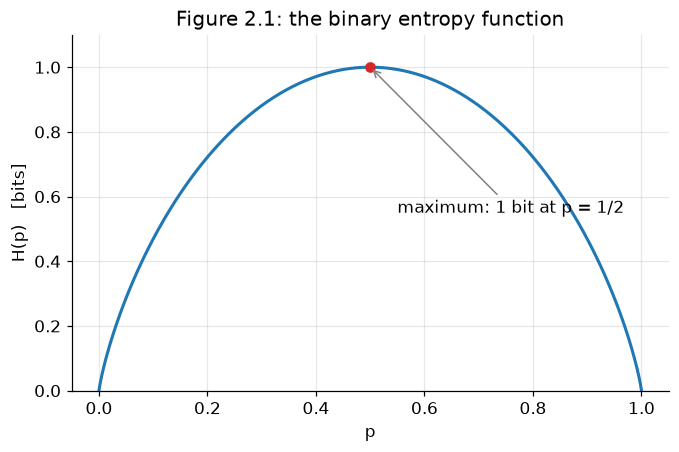

In [3]:
p_grid = np.linspace(0, 1, 501)

plt.plot(p_grid, it.binary_entropy(p_grid), color=it.COLORS["H"])
plt.plot([0.5], [1.0], "o", color=it.COLORS["D"])
plt.annotate("maximum: 1 bit at p = 1/2", xy=(0.5, 1.0), xytext=(0.55, 0.55),
             arrowprops=dict(arrowstyle="->", color="gray"))
plt.xlabel("p")
plt.ylabel("H(p)   [bits]")
plt.title("Figure 2.1: the binary entropy function")
plt.ylim(0, 1.1)
plt.show()

### A slider

Move the slider to see where a given $p$ sits on the curve. If `ipywidgets`
is not installed the cell still runs and draws one fixed value.

In [5]:
def show_binary_entropy(p=0.3):
    plt.figure()
    plt.plot(p_grid, it.binary_entropy(p_grid), color=it.COLORS["H"])
    plt.plot([p], [it.binary_entropy(p)], "o", color=it.COLORS["D"], markersize=9)
    plt.vlines(p, 0, it.binary_entropy(p), color=it.COLORS["bound"], linestyles="dashed")
    plt.xlabel("p")
    plt.ylabel("H(p)   [bits]")
    plt.title(f"p = {p:.2f},   H(p) = {float(it.binary_entropy(p)):.4f} bits")
    plt.ylim(0, 1.1)
    plt.show()


try:
    from ipywidgets import interact, FloatSlider
    interact(show_binary_entropy,
             p=FloatSlider(min=0.0, max=1.0, step=0.01, value=0.3))
except ImportError:
    show_binary_entropy(0.3)
    print("(install ipywidgets to get the slider)")

interactive(children=(FloatSlider(value=0.3, description='p', max=1.0, step=0.01), Output()), _dom_classes=('w…

## 1.3 Example 2.1.2: entropy and the number of yes-or-no questions

Let $X$ take the values $a, b, c, d$ with probabilities
$\tfrac12, \tfrac14, \tfrac18, \tfrac18$. Then

$$H(X) = \tfrac12 \log 2 + \tfrac14 \log 4 + \tfrac18 \log 8 + \tfrac18 \log 8
= \tfrac74 \text{ bits}.$$

Now suppose we must determine the value of $X$ using yes-or-no questions. A
good strategy is to ask "is $X = a$?", then "is $X = b$?", then "is $X = c$?".
The number of questions is 1, 2, 3, 3 respectively. Its expected value is

$$1 \cdot \tfrac12 + 2 \cdot \tfrac14 + 3 \cdot \tfrac18 + 3 \cdot \tfrac18 = 1.75,$$

exactly $H(X)$. Let us verify this by simulation.

In [6]:
values = np.array(["a", "b", "c", "d"])
p = np.array([1/2, 1/4, 1/8, 1/8])

print("H(X) =", it.entropy(p), "bits   (7/4 =", 7/4, ")")


def number_of_questions(x):
    """Questions asked by the strategy: is X = a? is X = b? is X = c?"""
    if x == "a":
        return 1
    if x == "b":
        return 2
    return 3            # c or d: identified after the third question


n_samples = 200_000
sample = rng.choice(values, size=n_samples, p=p)
questions = np.array([number_of_questions(x) for x in sample])

print("average number of questions over", n_samples, "trials =", questions.mean())
print("H(X)                                                 =", it.entropy(p))

H(X) = 1.75 bits   (7/4 = 1.75 )
average number of questions over 200000 trials = 1.74709
H(X)                                                 = 1.75


The agreement is not a coincidence for this distribution: the probabilities
are powers of $1/2$, and the strategy asks exactly $\log_2 (1/p(x))$ questions
for each value. In Chapter 5 the book shows that in general the minimum
expected number of binary questions lies between $H(X)$ and $H(X) + 1$.

The next cell shows the general bound on a distribution that is *not* dyadic.

In [7]:
q = np.array([0.4, 0.3, 0.2, 0.1])          # <-- change these four numbers
H_q = it.entropy(q)

# A simple strategy: ask "is X = 1?", "is X = 2?", "is X = 3?" in order.
questions_per_value = np.array([1, 2, 3, 3])
expected_questions = float(np.sum(q * questions_per_value))

print(f"H(X)                = {H_q:.4f} bits")
print(f"expected questions  = {expected_questions:.4f}")
print(f"H(X) + 1            = {H_q + 1:.4f}")
it.check("H(X) <= expected questions <= H(X) + 1",
         H_q <= expected_questions + 1e-12 and expected_questions <= H_q + 1 + 1e-12)

H(X)                = 1.8464 bits
expected questions  = 1.9000
H(X) + 1            = 2.8464
[PASS] H(X) <= expected questions <= H(X) + 1


True

## 1.4 Lemma 2.1.1 and Lemma 2.1.2

**Lemma 2.1.1.** $H(X) \ge 0$, because $0 \le p(x) \le 1$ implies
$\log \frac{1}{p(x)} \ge 0$.

**Lemma 2.1.2.** $H_b(X) = (\log_b a)\, H_a(X)$: changing the base of the
logarithm only multiplies the entropy by a constant. Going from bits to nats
means multiplying by $\ln 2 \approx 0.693$.

In [8]:
n_tests = 5000
smallest = np.inf
for _ in range(n_tests):
    k = rng.integers(2, 9)
    pk = it.random_pmf(k, rng)
    smallest = min(smallest, it.entropy(pk))

it.check(f"H >= 0 on {n_tests} random distributions",
         smallest >= 0, f"smallest value seen: {smallest:.6f}")

p = np.array([0.5, 0.2, 0.2, 0.1])
H_bits = it.entropy(p)
H_nats = -np.sum(p * np.log(p))                      # natural logarithm
it.check("H_nats = ln(2) * H_bits",
         np.isclose(H_nats, np.log(2) * H_bits),
         f"{H_nats:.6f} nats  =  {H_bits:.6f} bits x {np.log(2):.6f}")

[PASS] H >= 0 on 5000 random distributions   smallest value seen: 0.016672
[PASS] H_nats = ln(2) * H_bits   1.220607 nats  =  1.760964 bits x 0.693147


True

## 1.5 Entropy as a long-run average

The definition can be read as an expectation,

$$H(X) = \mathbb E_p \left[ \log \frac{1}{p(X)} \right].$$

So if we draw $X_1, X_2, \dots$ independently from $p$ and average the
quantity $\log \frac{1}{p(X_i)}$, the law of large numbers says the average
converges to $H(X)$. This is exactly the picture that becomes the asymptotic
equipartition property in Chapter 3.

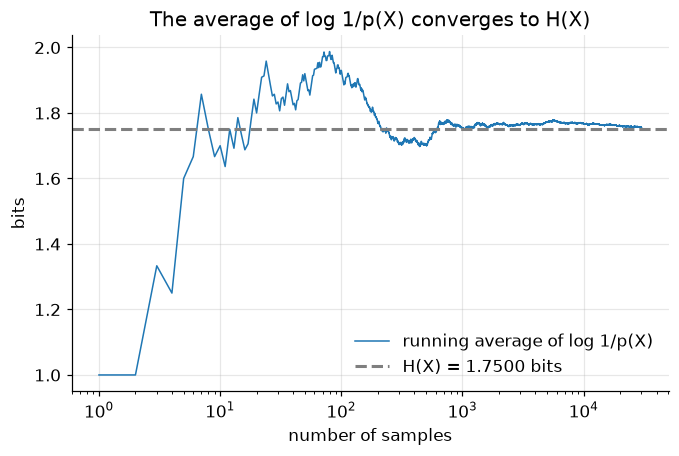

In [9]:
p = np.array([0.5, 0.25, 0.125, 0.125])     # <-- change this distribution
n = 30_000

index = rng.choice(len(p), size=n, p=p)
surprise = -np.log2(p[index])               # log 1/p(X_i) for each draw
running_average = np.cumsum(surprise) / np.arange(1, n + 1)

plt.plot(np.arange(1, n + 1), running_average, color=it.COLORS["H"],
         linewidth=1.0, label="running average of log 1/p(X)")
plt.axhline(it.entropy(p), color=it.COLORS["bound"], linestyle="--",
            label=f"H(X) = {it.entropy(p):.4f} bits")
plt.xscale("log")
plt.xlabel("number of samples")
plt.ylabel("bits")
plt.title("The average of log 1/p(X) converges to H(X)")
plt.legend()
plt.show()

## 1.6 Estimating entropy when $p$ is unknown

In practice we usually do not know $p$ and must estimate $H$ from data. The
simplest estimator replaces $p$ by the observed relative frequencies:

$$\hat H = -\sum_x \hat p(x) \log \hat p(x), \qquad
\hat p(x) = \frac{\text{number of times } x \text{ was seen}}{n}.$$

This *plug-in* estimator is **biased downwards**: with few samples some
outcomes are missed entirely, the estimated distribution looks more
concentrated than the true one, and $\hat H$ comes out too small. The plot
below shows the bias disappearing as $n$ grows.

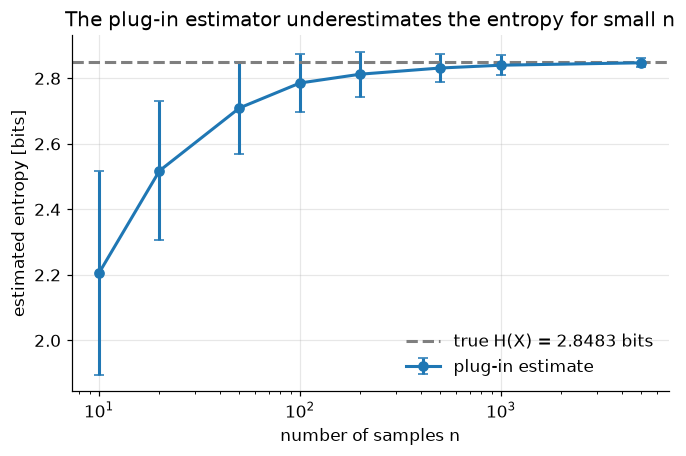

[PASS] plug-in estimate is below the truth for n = 10   2.2055 < 2.8483


True

In [10]:
p_true = it.random_pmf(10, rng)             # a random distribution on 10 outcomes
H_true = it.entropy(p_true)

sample_sizes = [10, 20, 50, 100, 200, 500, 1000, 5000]
n_repeats = 200

means, spreads = [], []
for n in sample_sizes:
    estimates = []
    for _ in range(n_repeats):
        draws = rng.choice(len(p_true), size=n, p=p_true)
        counts = np.bincount(draws, minlength=len(p_true))
        estimates.append(it.entropy(counts / n))
    means.append(np.mean(estimates))
    spreads.append(np.std(estimates))

plt.errorbar(sample_sizes, means, yerr=spreads, marker="o",
             color=it.COLORS["H"], capsize=3, label="plug-in estimate")
plt.axhline(H_true, color=it.COLORS["bound"], linestyle="--",
            label=f"true H(X) = {H_true:.4f} bits")
plt.xscale("log")
plt.xlabel("number of samples n")
plt.ylabel("estimated entropy [bits]")
plt.title("The plug-in estimator underestimates the entropy for small n")
plt.legend()
plt.show()

it.check("plug-in estimate is below the truth for n = 10",
         means[0] < H_true, f"{means[0]:.4f} < {H_true:.4f}")

## 1.7 How large can the entropy be?

Among all distributions on $m$ outcomes, the uniform one has the largest
entropy, and that largest value is $\log m$. This is Theorem 2.6.4 and it is
proved in notebook 05. Here we only look at it.

In [11]:
m = 6
n_tests = 20_000
best = 0.0
for _ in range(n_tests):
    best = max(best, it.entropy(it.random_pmf(m, rng)))

print(f"largest entropy found among {n_tests} random distributions on {m} outcomes: {best:.6f}")
print(f"entropy of the uniform distribution on {m} outcomes:                        {np.log2(m):.6f}")
it.check(f"H <= log2({m}) on all of them", best <= np.log2(m) + 1e-12)

largest entropy found among 20000 random distributions on 6 outcomes: 2.573834
entropy of the uniform distribution on 6 outcomes:                        2.584963
[PASS] H <= log2(6) on all of them


True

## Things to try

1. In Section 1.3, change `q` to a distribution that is very close to uniform
   and then to one that is very concentrated. When is the simple questioning
   strategy close to optimal, and when is it wasteful?
2. In Section 1.5, use a nearly deterministic distribution such as
   `p = [0.98, 0.01, 0.005, 0.005]`. How many samples are needed before the
   running average settles? Why does a rare outcome make convergence slow?
3.  A coin is flipped until the first head appears. Let $X$ be the number of
   flips. Compute $H(X)$ numerically by truncating the geometric distribution
   at a large value, and compare with the exact answer 2 bits for a fair coin
   (this is Problem 2.1 of the book).